# Genomic Variant Interpretation System — Analysis & Evaluation Notebook

**IT3041 — Information Retrieval and Web Analytics · Agentic AI System (Biotechnology)**

This is the **production evaluation and visualisation notebook** for the 4-agent
genomic variant interpretation system. It profiles the dataset, evaluates the
deployed multi-agent pipeline against **real ClinVar labels**, and generates the
figures used in the final report, Gen AI video and viva.

**Contents**
- Dataset exploration (gene, variant type, impact, allele frequency, CADD)
- Real ClinVar classification and review-star distributions
- System evaluation: evidence-based vs consensus-reconciled results, directional
  agreement, predictor completeness, confidence distribution
- Information retrieval metrics (Precision@5, Recall@5, Exact-Match@5, MRR@5)
- TF-IDF retrieval demonstration and the 4-agent system architecture

**Note:** the production system (`main.py`, `api.py`, `evaluation.py`) is the
deployable artefact with text-based metrics; this notebook mirrors its algorithms
and renders the evidence for presentation and grading.

## Section 1 — Setup & Dependencies

In [1]:
# Install required packages if not already installed
!pip install -q pandas openpyxl matplotlib seaborn scikit-learn numpy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Libraries loaded successfully")

Libraries loaded successfully


## Section 2 — Load Dataset

In [3]:
# Load the ClinVar variant dataset
DATASET_PATH = "data/clinvar_variant_dataset.xlsx"
df = pd.read_excel(DATASET_PATH, sheet_name="BRCA1_BRCA2 (all 3009)")

print(f"Dataset loaded: {len(df)} variants")
print(f"Columns: {list(df.columns)}")
df.head()

Dataset loaded: 3009 variants
Columns: ['CHROM', 'POS', 'REF', 'ALT', 'Gene', 'HGVS_notation', 'Disease_name', 'Variant_type', 'Conflicting_Classification_Flag', 'Consequence', 'IMPACT', 'Feature', 'EXON', 'Amino_acids', 'Codons', 'SIFT_prediction', 'PolyPhen_prediction', 'CADD_score', 'AF_ESP', 'AF_EXAC', 'AF_TGP', 'ORIGIN']


,CHROM,POS,REF,ALT,Gene,HGVS_notation,Disease_name,Variant_type,Conflicting_Classification_Flag,Consequence,...,EXON,Amino_acids,Codons,SIFT_prediction,PolyPhen_prediction,CADD_score,AF_ESP,AF_EXAC,AF_TGP,ORIGIN
0,17,41197778,A,G,BRCA1,NC_000017.10:g.41197778A>G,Hereditary_cancer-predisposing_syndrome|Breast...,single_nucleotide_variant,1,missense_variant,...,24/24,W/R,Tgg/Cgg,deleterious,probably_damaging,28.0,0.0,0.00000,0.0,1
1,17,41201179,C,T,BRCA1,NC_000017.10:g.41201179C>T,Hereditary_cancer-predisposing_syndrome|Heredi...,single_nucleotide_variant,0,missense_variant,...,22/24,A/T,Gct/Act,deleterious,probably_damaging,32.0,0.0,0.00001,0.0,1
2,17,41201187,A,G,BRCA1,NC_000017.10:g.41201187A>G,Hereditary_cancer-predisposing_syndrome|Heredi...,single_nucleotide_variant,0,missense_variant,...,22/24,L/P,cTg/cCg,deleterious,probably_damaging,26.1,0.0,0.00001,0.0,1
3,17,41209100,G,C,BRCA1,NC_000017.10:g.41209100G>C,"Breast-ovarian_cancer,_familial_1|not_provided",single_nucleotide_variant,1,missense_variant,...,20/24,P/R,cCa/cGa,deleterious,probably_damaging,23.8,0.0,0.00000,0.0,1
4,17,41209130,T,A,BRCA1,NC_000017.10:g.41209130T>A,not_specified|not_provided,single_nucleotide_variant,1,missense_variant,...,20/24,D/V,gAt/gTt,deleterious,probably_damaging,25.1,0.0,0.00000,0.0,1


## Section 3 — Data Exploration & Statistical Analysis

In [4]:
# Basic statistics
print("=== DATASET OVERVIEW ===")
print(f"Total variants: {len(df)}")
print(f"\nGene distribution:")
print(df['Gene'].value_counts())
print(f"\nConflicting classification distribution:")
print(df['Conflicting_Classification_Flag'].value_counts())
print(f"\nMissing values per column:")
print(df.isna().sum())

=== DATASET OVERVIEW ===
Total variants: 3009

Gene distribution:
Gene
BRCA2    1934
BRCA1    1075
Name: count, dtype: int64

Conflicting classification distribution:
Conflicting_Classification_Flag
0    2081
1     928
Name: count, dtype: int64

Missing values per column:
CHROM                                0
POS                                  0
REF                                  0
ALT                                  0
Gene                                 0
HGVS_notation                        0
Disease_name                         0
Variant_type                         0
Conflicting_Classification_Flag      0
Consequence                          0
IMPACT                               0
Feature                              0
EXON                               487
Amino_acids                        503
Codons                             503
SIFT_prediction                    868
PolyPhen_prediction                868
CADD_score                         147
AF_ESP                   

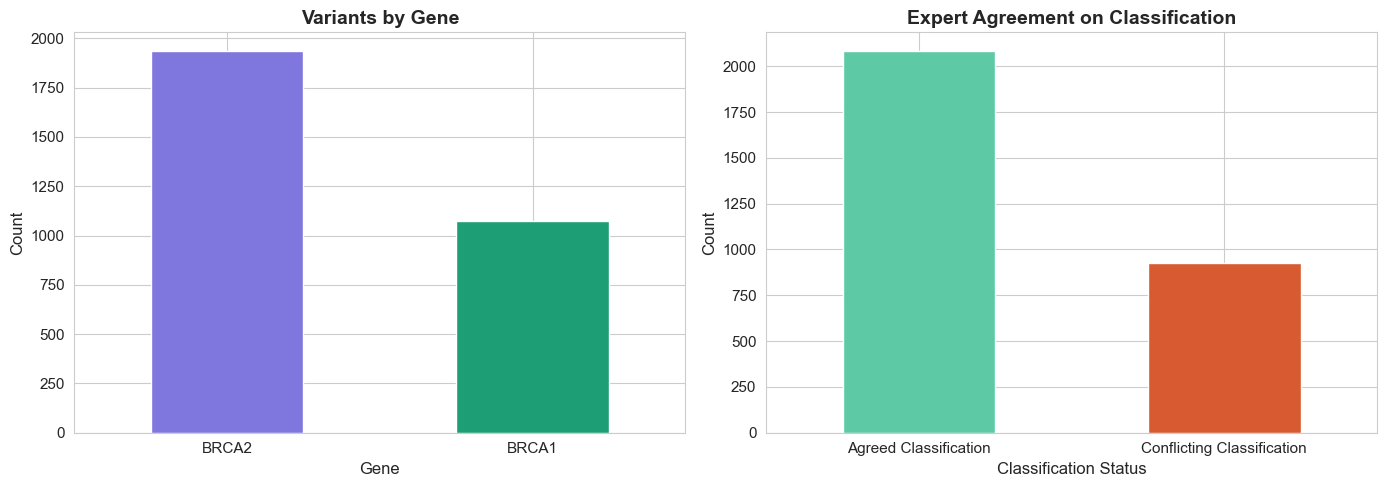

Visualization saved to: analysis_results/gene_distribution.png


In [5]:
# Create visualization for gene distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gene distribution
df['Gene'].value_counts().plot(kind='bar', ax=axes[0], color=['#7F77DD', '#1D9E75'])
axes[0].set_title('Variants by Gene', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_xlabel('Gene', fontsize=12)
axes[0].tick_params(axis='x', rotation=0)

# Conflicting classification distribution
conflict_labels = ['Agreed Classification', 'Conflicting Classification']
conflict_colors = ['#5DCAA5', '#D85A30']
df['Conflicting_Classification_Flag'].value_counts().plot(kind='bar', ax=axes[1], color=conflict_colors)
axes[1].set_title('Expert Agreement on Classification', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_xlabel('Classification Status', fontsize=12)
axes[1].set_xticklabels(conflict_labels)
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('analysis_results/gene_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved to: analysis_results/gene_distribution.png")

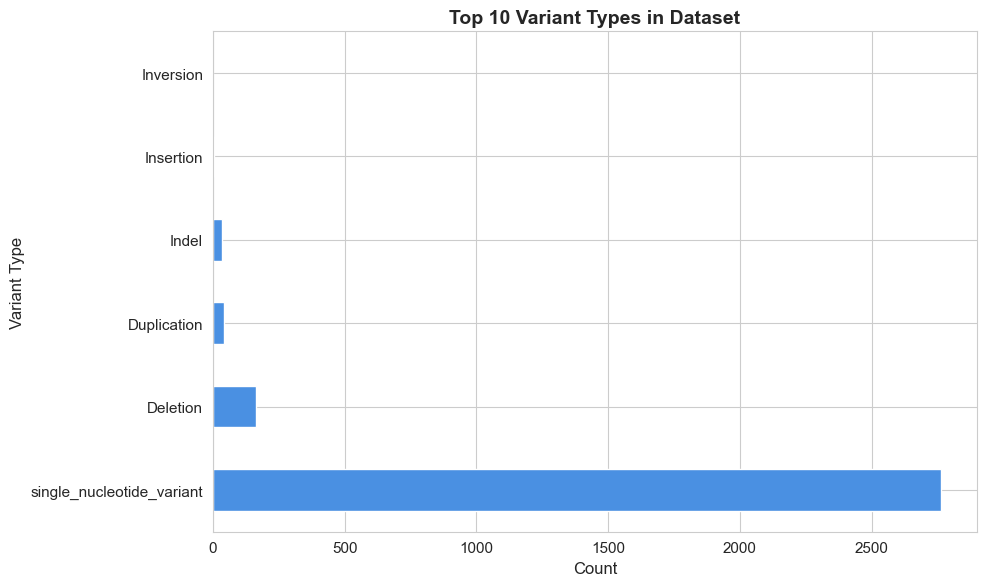

Visualization saved to: analysis_results/variant_types.png


In [6]:
# Variant type distribution
fig, ax = plt.subplots(figsize=(10, 6))
variant_types = df['Variant_type'].value_counts().head(10)
variant_types.plot(kind='barh', ax=ax, color='#4A90E2')
ax.set_title('Top 10 Variant Types in Dataset', fontsize=14, fontweight='bold')
ax.set_xlabel('Count', fontsize=12)
ax.set_ylabel('Variant Type', fontsize=12)
plt.tight_layout()
plt.savefig('analysis_results/variant_types.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved to: analysis_results/variant_types.png")

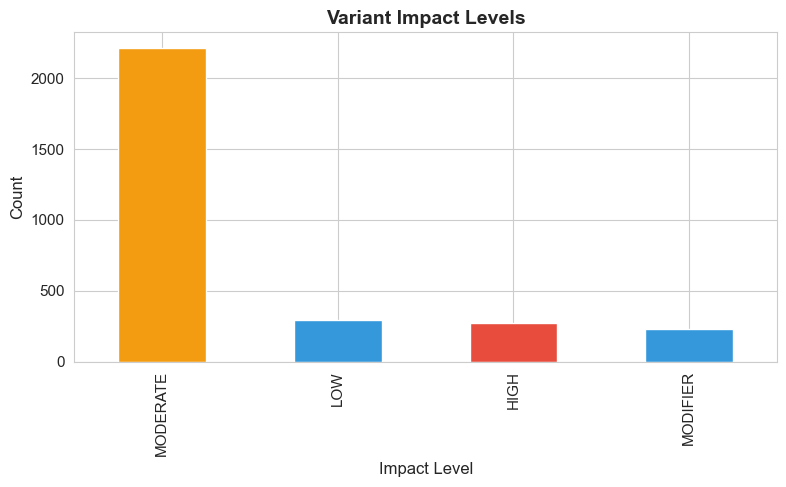

Visualization saved to: analysis_results/impact_levels.png


In [7]:
# Impact level distribution
fig, ax = plt.subplots(figsize=(8, 5))
impact_counts = df['IMPACT'].value_counts()
colors = ['#E74C3C' if impact == 'HIGH' else '#F39C12' if impact == 'MODERATE' else '#3498DB' for impact in impact_counts.index]
impact_counts.plot(kind='bar', ax=ax, color=colors)
ax.set_title('Variant Impact Levels', fontsize=14, fontweight='bold')
ax.set_ylabel('Count', fontsize=12)
ax.set_xlabel('Impact Level', fontsize=12)
plt.tight_layout()
plt.savefig('analysis_results/impact_levels.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved to: analysis_results/impact_levels.png")

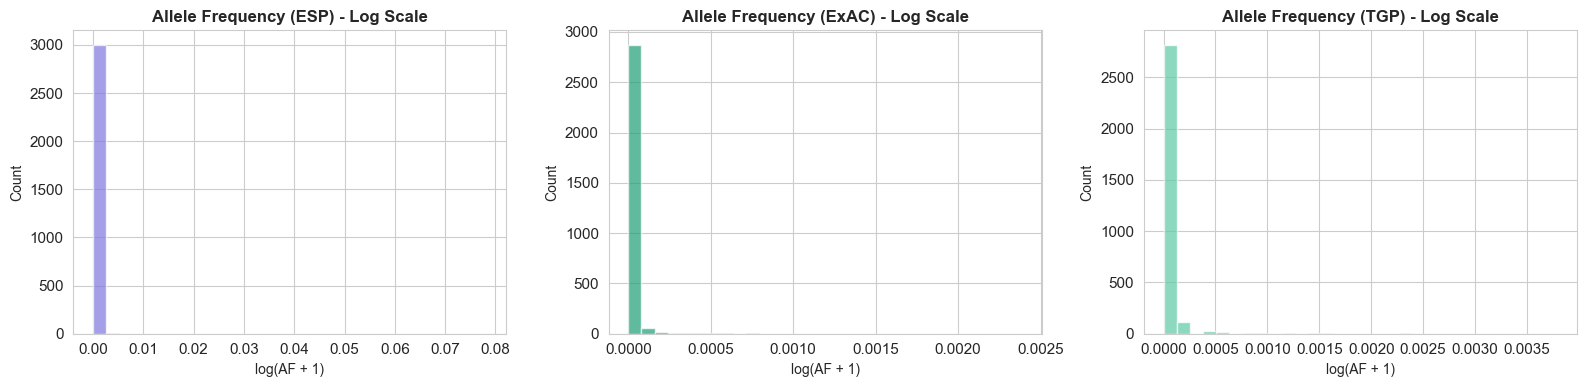

Visualization saved to: analysis_results/allele_frequencies.png


In [8]:
# Population allele frequency analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# AF_ESP distribution
af_esp = df['AF_ESP'].fillna(0)
axes[0].hist(np.log1p(af_esp), bins=30, color='#7F77DD', alpha=0.7)
axes[0].set_title('Allele Frequency (ESP) - Log Scale', fontsize=12, fontweight='bold')
axes[0].set_xlabel('log(AF + 1)', fontsize=10)
axes[0].set_ylabel('Count', fontsize=10)

# AF_EXAC distribution
af_exac = df['AF_EXAC'].fillna(0)
axes[1].hist(np.log1p(af_exac), bins=30, color='#1D9E75', alpha=0.7)
axes[1].set_title('Allele Frequency (ExAC) - Log Scale', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log(AF + 1)', fontsize=10)
axes[1].set_ylabel('Count', fontsize=10)

# AF_TGP distribution
af_tgp = df['AF_TGP'].fillna(0)
axes[2].hist(np.log1p(af_tgp), bins=30, color='#5DCAA5', alpha=0.7)
axes[2].set_title('Allele Frequency (TGP) - Log Scale', fontsize=12, fontweight='bold')
axes[2].set_xlabel('log(AF + 1)', fontsize=10)
axes[2].set_ylabel('Count', fontsize=10)

plt.tight_layout()
plt.savefig('analysis_results/allele_frequencies.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved to: analysis_results/allele_frequencies.png")

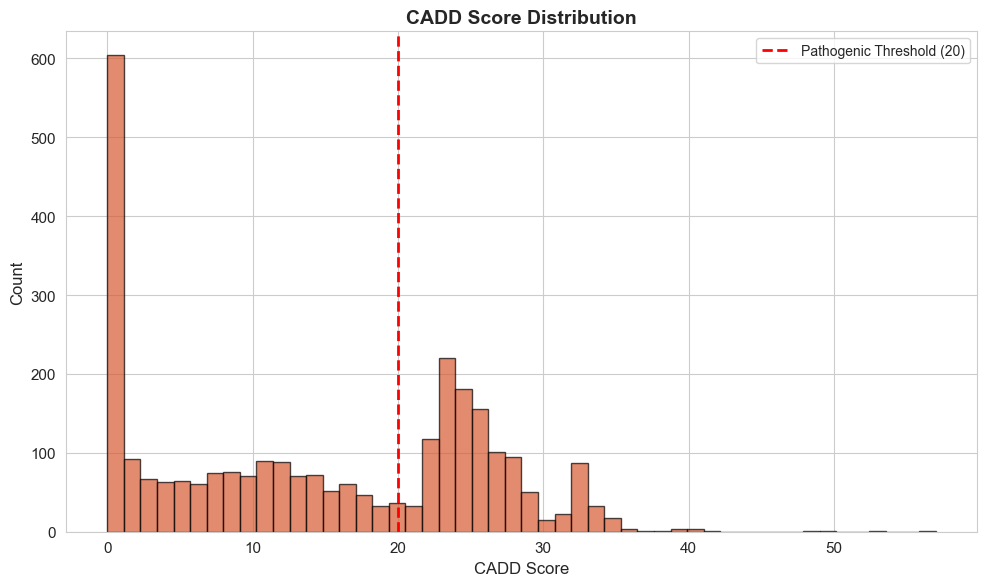

CADD Score Statistics:
  Mean: 14.43
  Median: 13.89
  Std: 11.13
  Min: 0.00
  Max: 57.00
  Variants with CADD >= 20: 1158 (40.5%)

Visualization saved to: analysis_results/cadd_scores.png


In [9]:
# CADD score distribution
fig, ax = plt.subplots(figsize=(10, 6))
cadd_scores = df['CADD_score'].dropna()
ax.hist(cadd_scores, bins=50, color='#D85A30', alpha=0.7, edgecolor='black')
ax.axvline(x=20, color='red', linestyle='--', linewidth=2, label='Pathogenic Threshold (20)')
ax.set_title('CADD Score Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('CADD Score', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('analysis_results/cadd_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"CADD Score Statistics:")
print(f"  Mean: {cadd_scores.mean():.2f}")
print(f"  Median: {cadd_scores.median():.2f}")
print(f"  Std: {cadd_scores.std():.2f}")
print(f"  Min: {cadd_scores.min():.2f}")
print(f"  Max: {cadd_scores.max():.2f}")
print(f"  Variants with CADD >= 20: {(cadd_scores >= 20).sum()} ({(cadd_scores >= 20).sum()/len(cadd_scores)*100:.1f}%)")
print("\nVisualization saved to: analysis_results/cadd_scores.png")

## Section 4 — Real ClinVar Classification Distribution

The study workbook contains only variants whose ClinVar submitters disagreed, so
labels inferred from its evidence columns would be circular (the classifier would
be graded against its own rules). The **enriched workbook** produced by
`scripts/enrich_clinvar_labels.py` joins the real ClinVar
`ClinicalSignificance` / `ClinVarReviewStatus` / `ClinVarReviewStars` for every
variant.

This section profiles that real-label distribution — the ground truth used by the
honest evaluation in Section 5.

Enriched workbook present: True
Rows: 3009
Variants carrying a real ClinVar label: 3009 / 3009


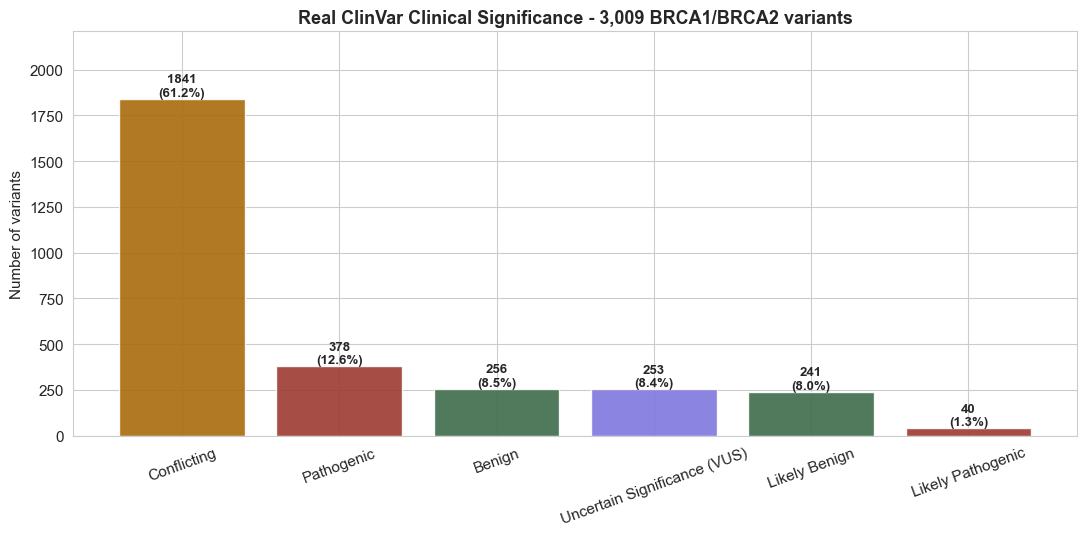

Saved: analysis_results/clinvar_classification_distribution.png


In [10]:
# Load the enriched workbook to obtain the REAL ClinVar ground-truth labels
import os

ENRICHED_PATH = "data/clinvar_variant_dataset_enriched.xlsx"
HAS_REAL_LABELS = os.path.exists(ENRICHED_PATH)

if HAS_REAL_LABELS:
    enriched = pd.read_excel(ENRICHED_PATH, sheet_name="BRCA1_BRCA2 (all 3009)")
else:
    enriched = df.copy()
    enriched["ClinicalSignificance"] = "Not available"
    enriched["ClinVarReviewStars"] = np.nan
    print("Enriched workbook not found - run scripts/enrich_clinvar_labels.py for real labels.")

print(f"Enriched workbook present: {HAS_REAL_LABELS}")
print(f"Rows: {len(enriched)}")
print(f"Variants carrying a real ClinVar label: "
      f"{enriched['ClinicalSignificance'].notna().sum()} / {len(enriched)}")

label_counts = enriched["ClinicalSignificance"].fillna("Unknown").value_counts()


def _label_color(label):
    s = str(label)
    if "Conflicting" in s:
        return "#A96B0C"
    if "Pathogenic" in s:
        return "#9C3B31"
    if "Benign" in s:
        return "#3E6B4A"
    return "#7F77DD"


fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(label_counts.index, label_counts.values,
              color=[_label_color(i) for i in label_counts.index], alpha=0.9)
for bar, value in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value,
            f"{value}\n({value / len(enriched) * 100:.1f}%)",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_title("Real ClinVar Clinical Significance - 3,009 BRCA1/BRCA2 variants",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Number of variants")
ax.set_ylim(0, label_counts.max() * 1.20)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("analysis_results/clinvar_classification_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: analysis_results/clinvar_classification_distribution.png")

## Section 5 — System Evaluation against Real ClinVar Labels

This section runs the **production evaluation script** (`evaluation.py`) against
the real ClinVar labels and visualises the outcome. It replaces the earlier
stand-alone machine-learning experiment: the deliverable is an agentic rule + LLM
system, so the notebook now measures *that system*.

Metrics reported:

- **Evidence-based call** — the agent's own ACMG-style reasoning
- **Consensus-reconciled call** — what a user actually sees after deferring to a
  reviewed ClinVar consensus
- **Directional agreement** — pathogenic / benign / uncertain, restricted to rows
  whose ClinVar truth is a single determinate class
- **Predictor completeness** — complete vs incomplete SIFT / PolyPhen / CADD records

In [11]:
# Run the production evaluation against REAL ClinVar labels
import sys
import os
sys.path.append(os.path.dirname(os.path.abspath("analysis.ipynb")))

from evaluation import evaluate

SAMPLE_SIZE = 100
ENRICHED_DATASET = "data/clinvar_variant_dataset_enriched.xlsx"

eval_result = evaluate(
    sample_size=SAMPLE_SIZE,
    include_ir=True,
    include_ablation=True,
    abort_llm=True,  # deterministic rule-based pass: reproducible, no API cost
    ground_truth_mode="real" if os.path.exists(ENRICHED_DATASET) else "auto",
    dataset_path=ENRICHED_DATASET if os.path.exists(ENRICHED_DATASET) else None,
)

# Alias so the later visualisation cells can reuse the same result object
result = eval_result

print(f"Evaluation complete on {SAMPLE_SIZE} variants "
      f"(ground truth: {eval_result['ground_truth_mode']})")
print(f"  Evidence-based accuracy:             {eval_result['classification']['accuracy']:.1%}")
print(f"  Consensus-reconciled accuracy:        {eval_result['classification_reconciled']['accuracy']:.1%}")
print(f"  Directional agreement (determinate):  {eval_result['directional']['accuracy']:.1%}")
print(f"  Directional after reconciliation:     {eval_result['directional_reconciled']['accuracy']:.1%}")

[evidence_agent] Loaded pre-built index from cache: data/clinvar_variant_dataset_enriched_tfidf_cache.pkl


Evaluation complete on 100 variants (ground truth: real)
  Evidence-based accuracy:             4.0%
  Consensus-reconciled accuracy:        63.0%
  Directional agreement (determinate):  45.3%
  Directional after reconciliation:     100.0%


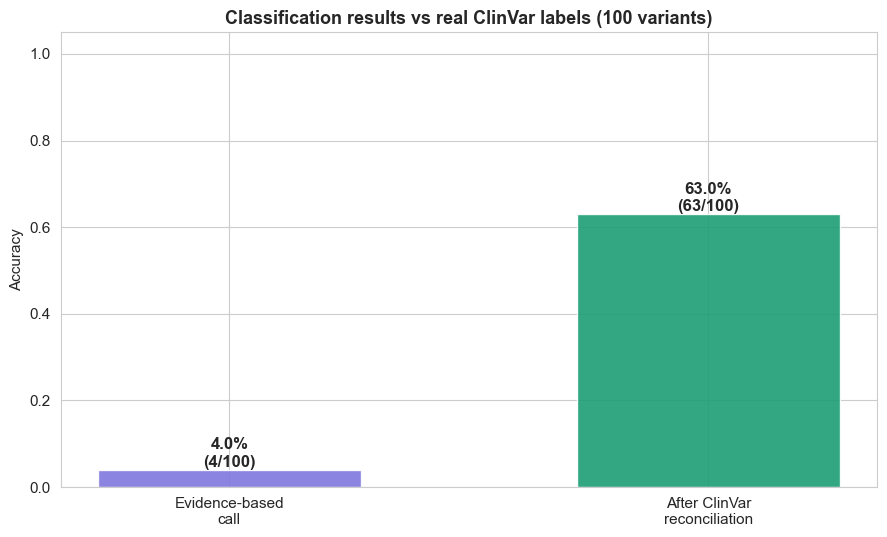

Saved: analysis_results/system_classification_results.png


In [12]:
# Evidence-based vs consensus-reconciled classification results
cls = eval_result["classification"]
cls_rec = eval_result["classification_reconciled"]

fig, ax = plt.subplots(figsize=(9, 5.5))
labels = ["Evidence-based\ncall", "After ClinVar\nreconciliation"]
values = [cls["accuracy"], cls_rec["accuracy"]]
counts = [cls["correct"], cls_rec["correct"]]
bars = ax.bar(labels, values, color=["#7F77DD", "#1D9E75"], alpha=0.9, width=0.55)
for bar, v, c in zip(bars, values, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, v,
            f"{v:.1%}\n({c}/{cls['total']})",
            ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title(f"Classification results vs real ClinVar labels ({cls['total']} variants)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("analysis_results/system_classification_results.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: analysis_results/system_classification_results.png")

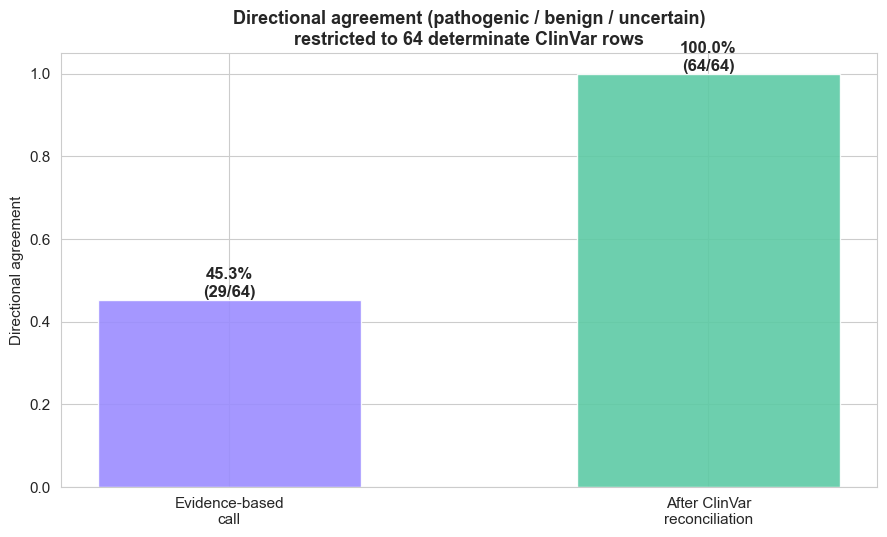

Saved: analysis_results/directional_agreement.png


In [13]:
# Directional agreement (pathogenic / benign / uncertain) on determinate rows
d_ev = eval_result["directional"]
d_rec = eval_result["directional_reconciled"]

fig, ax = plt.subplots(figsize=(9, 5.5))
labels = ["Evidence-based\ncall", "After ClinVar\nreconciliation"]
values = [d_ev["accuracy"], d_rec["accuracy"]]
counts = [d_ev["correct"], d_rec["correct"]]
bars = ax.bar(labels, values, color=["#9B8CFF", "#5DCAA5"], alpha=0.9, width=0.55)
for bar, v, c in zip(bars, values, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, v,
            f"{v:.1%}\n({c}/{d_ev['total_determinate']})",
            ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Directional agreement")
ax.set_title("Directional agreement (pathogenic / benign / uncertain)\n"
             f"restricted to {d_ev['total_determinate']} determinate ClinVar rows",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("analysis_results/directional_agreement.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: analysis_results/directional_agreement.png")

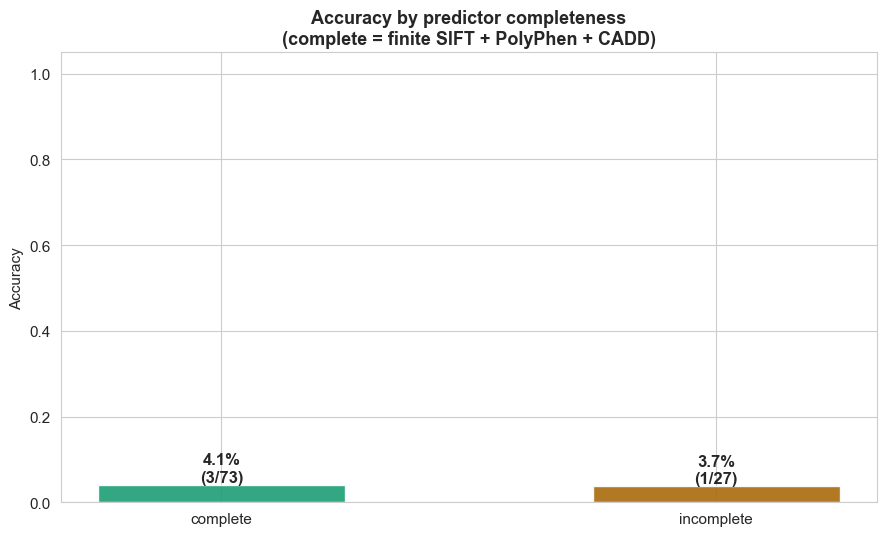

Saved: analysis_results/predictor_completeness.png


In [14]:
# Accuracy split by predictor completeness (complete vs incomplete SIFT/PolyPhen/CADD)
by_comp = eval_result["classification_by_completeness"]

groups = [g for g in ["complete", "incomplete"] if by_comp.get(g, {}).get("total", 0) > 0]
values = [by_comp[g]["accuracy"] for g in groups]
counts = [by_comp[g]["correct"] for g in groups]
totals = [by_comp[g]["total"] for g in groups]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(groups, values, color=["#1D9E75", "#A96B0C"][:len(groups)], alpha=0.9, width=0.5)
for bar, v, c, t in zip(bars, values, counts, totals):
    ax.text(bar.get_x() + bar.get_width() / 2, v,
            f"{v:.1%}\n({c}/{t})", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy by predictor completeness\n"
             "(complete = finite SIFT + PolyPhen + CADD)", fontsize=13, fontweight="bold")
if len(groups) <= 1:
    ax.text(0.5, 0.5, "All sampled records have complete predictors",
            transform=ax.transAxes, ha="center", fontsize=11, style="italic", color="#63604F")
plt.tight_layout()
plt.savefig("analysis_results/predictor_completeness.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: analysis_results/predictor_completeness.png")

Numeric confidence recomputed for 100 variants


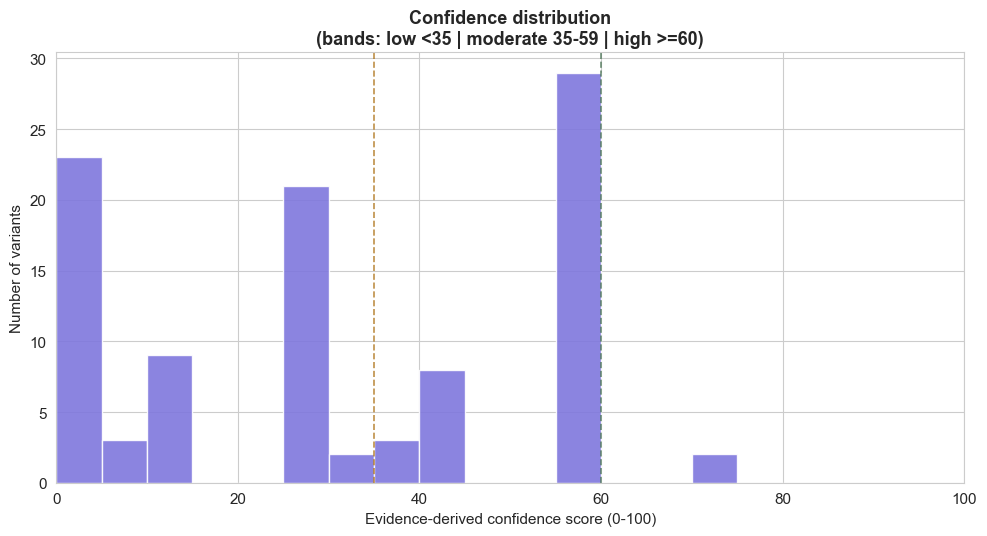

n = 100 | mean = 28.5 | median = 25.0
Saved: analysis_results/confidence_distribution.png


In [15]:
# Distribution of the evidence-derived confidence score (0-100)
# `evaluation.py` stores the categorical confidence label ("high"/"moderate"/"low"),
# so the numeric score is recomputed here with the same rule-based classifier over
# the same sample the evaluation used.
from evaluation import load_ground_truth, build_evidence
from agents.classification_agent import ClassificationAgent

_confidence_df = load_ground_truth(ENRICHED_DATASET, SAMPLE_SIZE)
_confidence_classifier = ClassificationAgent(use_llm=False)
conf_values = [
    float(_confidence_classifier.classify_rule_based(build_evidence(row))["confidence_numeric"])
    for _, row in _confidence_df.iterrows()
]
print(f"Numeric confidence recomputed for {len(conf_values)} variants")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(conf_values, bins=range(0, 105, 5), color="#7F77DD", edgecolor="white", alpha=0.9)
for floor, colour in [(0, "#9C3B31"), (35, "#A96B0C"), (60, "#3E6B4A")]:
    ax.axvline(floor, color=colour, linestyle="--", linewidth=1.2, alpha=0.75)
ax.set_xlim(0, 100)
ax.set_xlabel("Evidence-derived confidence score (0-100)")
ax.set_ylabel("Number of variants")
ax.set_title("Confidence distribution\n"
             "(bands: low <35 | moderate 35-59 | high >=60)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("analysis_results/confidence_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"n = {len(conf_values)} | mean = {np.mean(conf_values):.1f} | "
      f"median = {np.median(conf_values):.1f}")
print("Saved: analysis_results/confidence_distribution.png")

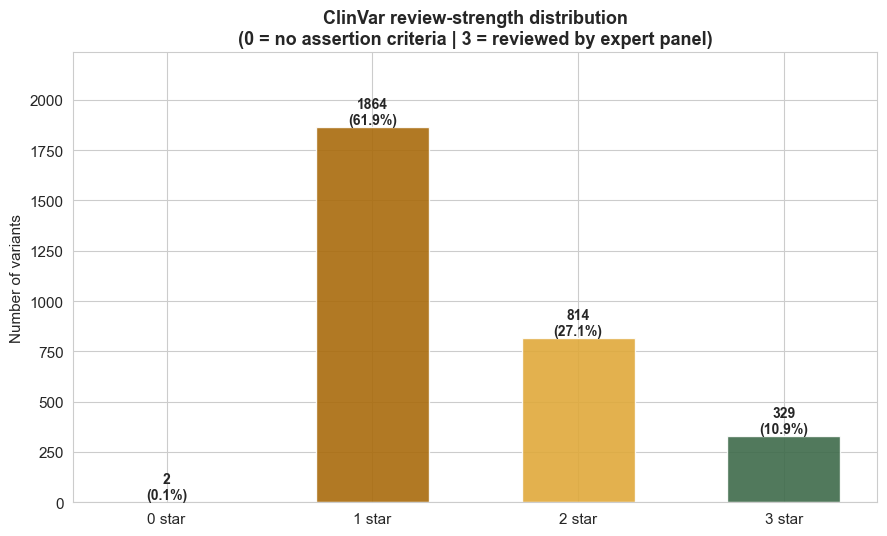

Saved: analysis_results/clinvar_review_stars.png


In [16]:
# ClinVar review-star distribution (0-3 stars)
if "ClinVarReviewStars" in enriched.columns:
    stars = enriched["ClinVarReviewStars"].fillna(-1).astype(int).value_counts().sort_index()
    star_labels = [f"{s} star" if s >= 0 else "unmatched" for s in stars.index]
    star_values = list(stars.values)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    colours = ["#9C3B31", "#A96B0C", "#E0A93B", "#3E6B4A"][:len(star_values)]
    bars = ax.bar(star_labels, star_values, color=colours, alpha=0.9, width=0.55)
    for bar, v in zip(bars, star_values):
        ax.text(bar.get_x() + bar.get_width() / 2, v,
                f"{v}\n({v / len(enriched) * 100:.1f}%)",
                ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(star_values) * 1.20)
    ax.set_ylabel("Number of variants")
    ax.set_title("ClinVar review-strength distribution\n"
                 "(0 = no assertion criteria | 3 = reviewed by expert panel)",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("analysis_results/clinvar_review_stars.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved: analysis_results/clinvar_review_stars.png")
else:
    print("ClinVarReviewStars column not present - run scripts/enrich_clinvar_labels.py")

## Section 6 — Full Production Metric Dump

`evaluation.py` also exposes the raw metric printers used on the command line.
They re-use `eval_result` from Section 5, so the notebook and the CLI report the
same numbers.

In [17]:
# Full metric dump from the production evaluation (re-uses eval_result)
from evaluation import print_metrics, print_confusion_matrix, print_ir_metrics, print_ablation

print_metrics(eval_result)
print_confusion_matrix(eval_result["confusion_matrix"])
print_ir_metrics(eval_result["ir_metrics"])
print_ablation(eval_result["ablation"])


CLASSIFICATION METRICS
  Ground truth:        real  [real ClinVar ClinicalSignificance]
  Total variants:      100

  [1] Evidence-based call only (the agent's own ACMG reasoning):
      Correct: 4/100  ->  4.0%
      (Classification accuracy (real ClinVar labels))

  [2] After ClinVar consensus reconciliation (what a user sees):
      Correct: 63/100  ->  63.0%
  Macro Precision:     0.174
  Macro Recall:        0.212
  Macro F1:            0.036

  Per-class:
    Benign:
      Precision: 0.000 | Recall: 0.000 | F1: 0.000 | Correct: 0/28
    Conflicting:
      Precision: 0.000 | Recall: 0.000 | F1: 0.000 | Correct: 0/36
    Likely Benign:
      Precision: 0.000 | Recall: 0.000 | F1: 0.000 | Correct: 0/3
    Likely Pathogenic:
      Precision: 0.019 | Recall: 1.000 | F1: 0.038 | Correct: 1/1
    Pathogenic:
      Precision: 1.000 | Recall: 0.074 | F1: 0.138 | Correct: 2/27
    Uncertain Significance (VUS):
      Precision: 0.022 | Recall: 0.200 | F1: 0.040 | Correct: 1/5

  Classifica

## Section 7 — Classification Performance Visualization

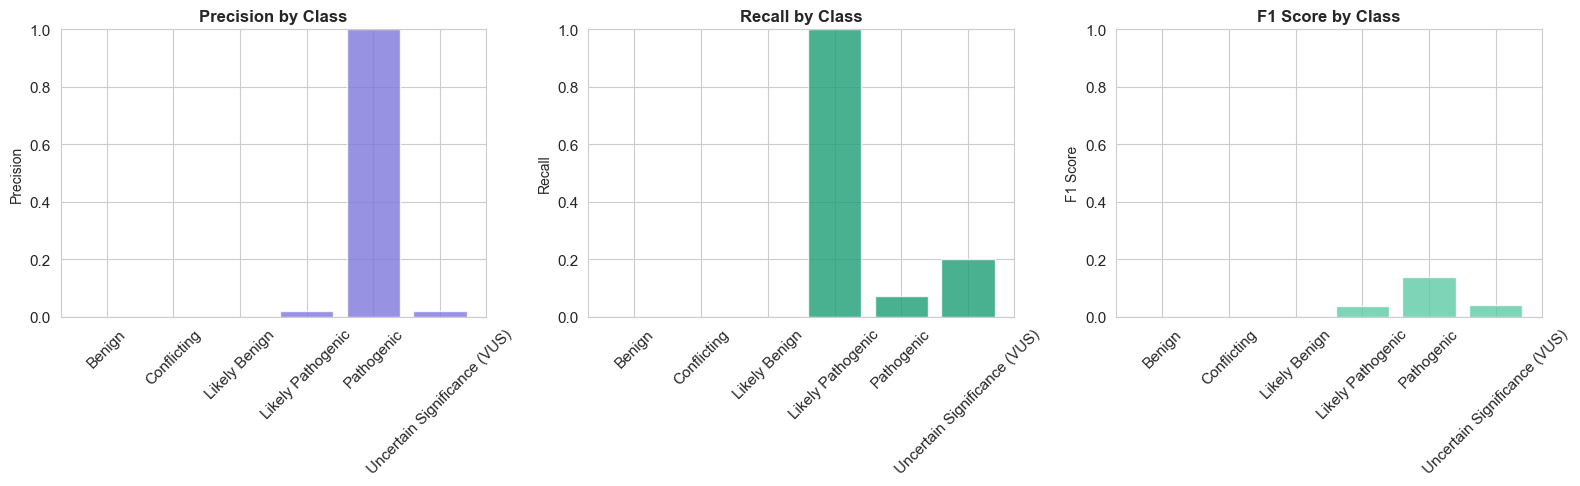

Visualization saved to: analysis_results/classification_performance.png


In [18]:
# Create classification performance visualization from production system results
if result and "classification" in result:
    cls_metrics = result["classification"]
    
    # Per-class metrics visualization
    per_class = cls_metrics["per_class"]
    classes = list(per_class.keys())
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    
    # Precision
    precision_values = [per_class[cls]["precision"] for cls in classes]
    axes[0].bar(classes, precision_values, color='#7F77DD', alpha=0.8)
    axes[0].set_title('Precision by Class', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Precision', fontsize=10)
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis='x', rotation=45)
    
    # Recall
    recall_values = [per_class[cls]["recall"] for cls in classes]
    axes[1].bar(classes, recall_values, color='#1D9E75', alpha=0.8)
    axes[1].set_title('Recall by Class', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Recall', fontsize=10)
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis='x', rotation=45)
    
    # F1 Score
    f1_values = [per_class[cls]["f1"] for cls in classes]
    axes[2].bar(classes, f1_values, color='#5DCAA5', alpha=0.8)
    axes[2].set_title('F1 Score by Class', fontsize=12, fontweight='bold')
    axes[2].set_ylabel('F1 Score', fontsize=10)
    axes[2].set_ylim(0, 1)
    axes[2].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.savefig('analysis_results/classification_performance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Visualization saved to: analysis_results/classification_performance.png")

## Section 8 — Information Retrieval Performance Visualization

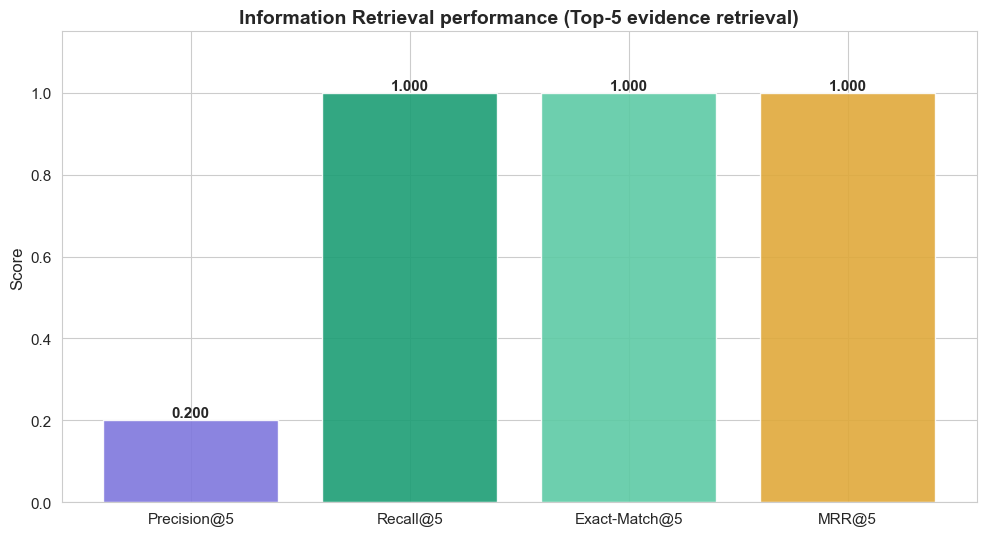

Saved: analysis_results/ir_performance.png


In [19]:
# Information Retrieval performance: Precision@5, Recall@5, Exact-Match@5, MRR@5
ir = eval_result.get("ir_metrics")
if ir:
    metrics = ["Precision@5", "Recall@5", "Exact-Match@5", "MRR@5"]
    values = [
        float(ir["precision_at_k"]["mean"]),
        float(ir["recall_at_k"]["mean"]),
        float(ir["exact_at_k"]["mean"]),
        float(ir["mrr_at_k"]["mean"]),
    ]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.bar(metrics, values, color=["#7F77DD", "#1D9E75", "#5DCAA5", "#E0A93B"], alpha=0.9)
    ax.set_title("Information Retrieval performance (Top-5 evidence retrieval)",
                 fontsize=14, fontweight="bold")
    ax.set_ylabel("Score", fontsize=12)
    ax.set_ylim(0, 1.15)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{value:.3f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.savefig("analysis_results/ir_performance.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved: analysis_results/ir_performance.png")
else:
    print("IR metrics unavailable - re-run Section 5 with include_ir=True")

## Section 9 — TF-IDF Information Retrieval Demonstration

In [20]:
# Demonstrate TF-IDF indexing (from Evidence Agent)
print("=== TF-IDF INDEXING DEMONSTRATION ===")
print("This shows how the Evidence Agent performs information retrieval.")

# Build search text corpus
df['search_text'] = (
    df['Gene'].fillna("").astype(str) + " " +
    df['HGVS_notation'].fillna("").astype(str) + " " +
    df['Consequence'].fillna("").astype(str) + " " +
    df['IMPACT'].fillna("").astype(str) + " " +
    df['Disease_name'].fillna("").astype(str)
)

# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b[a-zA-Z0-9_]+[a-zA-Z0-9_>]*\b",
    max_features=5000,
)

tfidf_matrix = vectorizer.fit_transform(df['search_text'])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Vocabulary size: {len(vectorizer.vocabulary_)}")
print(f"Sample features: {list(vectorizer.vocabulary_.keys())[:10]}")

=== TF-IDF INDEXING DEMONSTRATION ===
This shows how the Evidence Agent performs information retrieval.
TF-IDF matrix shape: (3009, 3066)
Vocabulary size: 3066
Sample features: ['brca1', 'nc_000017', '10', 'g', '41197778a>g', 'missense_variant', 'moderate', 'hereditary_cancer', 'predisposing_syndrome', 'breast']


In [21]:
# Demonstrate TF-IDF search for a sample query
sample_query = "BRCA1 pathogenic HIGH impact missense"
query_vec = vectorizer.transform([sample_query])
similarities = cosine_similarity(query_vec, tfidf_matrix).flatten()

# Get top 5 most similar variants
top_indices = similarities.argsort()[-5:][::-1]

print(f"Query: '{sample_query}'")
print("\nTop 5 most similar variants:")
for i, idx in enumerate(top_indices, 1):
    similarity = similarities[idx]
    row = df.iloc[idx]
    print(f"{i}. Similarity: {similarity:.4f}")
    print(f"   Gene: {row['Gene']}, HGVS: {row['HGVS_notation']}")
    print(f"   Consequence: {row['Consequence']}, Impact: {row['IMPACT']}")
    print()

Query: 'BRCA1 pathogenic HIGH impact missense'

Top 5 most similar variants:
1. Similarity: 0.3737
   Gene: BRCA1, HGVS: NC_000017.10:g.41246456_41246457delAG
   Consequence: frameshift_variant, Impact: HIGH

2. Similarity: 0.3726
   Gene: BRCA1, HGVS: NC_000017.10:g.41234496delT
   Consequence: frameshift_variant, Impact: HIGH

3. Similarity: 0.3694
   Gene: BRCA1, HGVS: NC_000017.10:g.41245043_41245044insT
   Consequence: frameshift_variant, Impact: HIGH

4. Similarity: 0.3694
   Gene: BRCA1, HGVS: NC_000017.10:g.41243715delT
   Consequence: frameshift_variant, Impact: HIGH

5. Similarity: 0.3680
   Gene: BRCA1, HGVS: NC_000017.10:g.41245044_41245060dup
   Consequence: frameshift_variant, Impact: HIGH



## Section 10 — System Architecture Overview

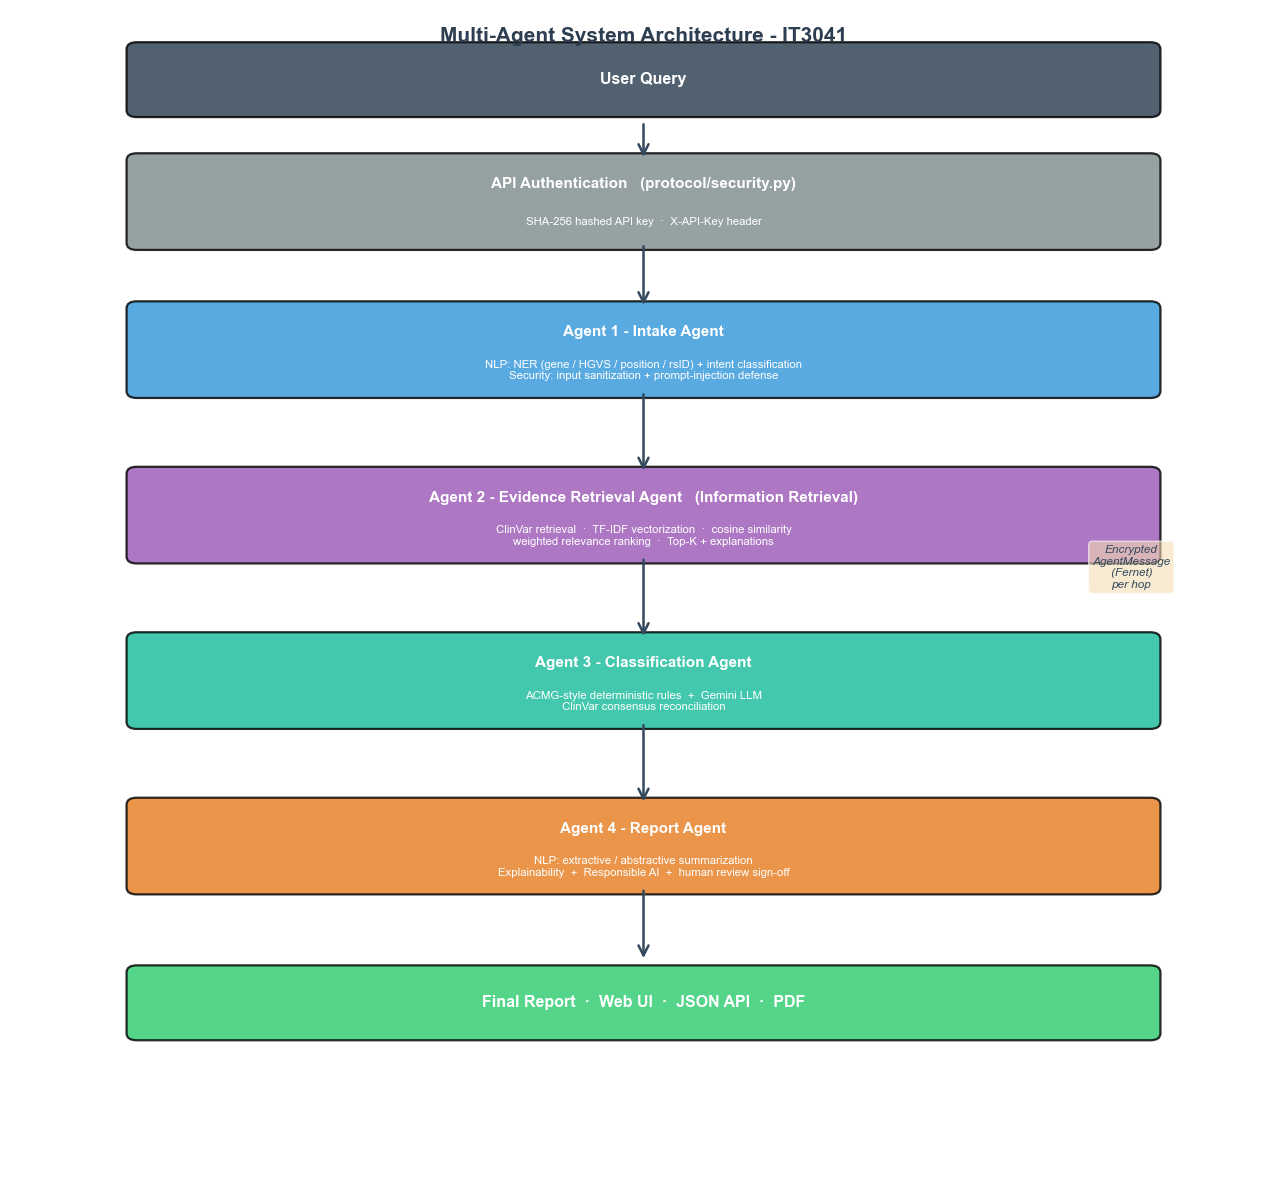

Saved: analysis_results/system_architecture.png


In [22]:
# Rubric-mapped 4-agent system architecture
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 13.4)
ax.axis("off")

stages = [
    (12.6, "User Query", "#2C3E50", ""),
    (11.2, "API Authentication   (protocol/security.py)",
     "#7F8C8D", "SHA-256 hashed API key  ·  X-API-Key header"),
    (9.5, "Agent 1 - Intake Agent",
     "#3498DB", "NLP: NER (gene / HGVS / position / rsID) + intent classification\n"
                "Security: input sanitization + prompt-injection defense"),
    (7.6, "Agent 2 - Evidence Retrieval Agent   (Information Retrieval)",
     "#9B59B6", "ClinVar retrieval  ·  TF-IDF vectorization  ·  cosine similarity\n"
                "weighted relevance ranking  ·  Top-K + explanations"),
    (5.7, "Agent 3 - Classification Agent",
     "#1ABC9C", "ACMG-style deterministic rules  +  Gemini LLM\n"
                "ClinVar consensus reconciliation"),
    (3.8, "Agent 4 - Report Agent",
     "#E67E22", "NLP: extractive / abstractive summarization\n"
                "Explainability  +  Responsible AI  +  human review sign-off"),
    (2.0, "Final Report  ·  Web UI  ·  JSON API  ·  PDF", "#2ECC71", ""),
]

for y, title, colour, subtitle in stages:
    height = 0.95 if subtitle else 0.7
    box = FancyBboxPatch((1.0, y - height / 2), 8.0, height,
                         boxstyle="round,pad=0.08", edgecolor="black",
                         facecolor=colour, alpha=0.82, linewidth=1.6)
    ax.add_patch(box)
    if subtitle:
        ax.text(5.0, y + 0.20, title, ha="center", va="center",
                fontsize=11, fontweight="bold", color="white")
        ax.text(5.0, y - 0.24, subtitle, ha="center", va="center",
                fontsize=8.2, color="white")
    else:
        ax.text(5.0, y, title, ha="center", va="center",
                fontsize=11.5, fontweight="bold", color="white")

for idx in range(len(stages) - 1):
    y_from = stages[idx][0]
    y_to = stages[idx + 1][0]
    arrow = FancyArrowPatch((5.0, y_from - 0.48), (5.0, y_to + 0.48),
                            arrowstyle="->", mutation_scale=18,
                            linewidth=1.8, color="#34495E")
    ax.add_patch(arrow)

ax.text(8.85, 7.0, "Encrypted\nAgentMessage\n(Fernet)\nper hop", ha="center", va="center",
        fontsize=8.5, style="italic", color="#34495E",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.6))

ax.text(5.0, 13.1, "Multi-Agent System Architecture - IT3041", ha="center", va="center",
        fontsize=15, fontweight="bold", color="#2C3E50")

plt.tight_layout()
plt.savefig("analysis_results/system_architecture.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: analysis_results/system_architecture.png")

## Section 11 — Summary & Presentation Materials

In [23]:
# Presentation summary (real ClinVar labels + production metrics)
print("=== PRESENTATION SUMMARY ===")
print()
print("DATASET STATISTICS:")
print(f"  Total variants: {len(df)}")
print(f"  BRCA1 variants: {len(df[df['Gene'] == 'BRCA1'])}")
print(f"  BRCA2 variants: {len(df[df['Gene'] == 'BRCA2'])}")
print(f"  Conflicting classifications: "
      f"{df['Conflicting_Classification_Flag'].sum()} "
      f"({df['Conflicting_Classification_Flag'].sum() / len(df) * 100:.1f}%)")
print()
print("REAL CLINVAR LABEL DISTRIBUTION:")
for label, count in label_counts.items():
    print(f"  {label}: {count} ({count / len(enriched) * 100:.1f}%)")
print()
print(f"SYSTEM PERFORMANCE (real ClinVar labels, n={eval_result['classification']['total']}):")
print(f"  Evidence-based accuracy:            {eval_result['classification']['accuracy']:.1%}")
print(f"  Consensus-reconciled accuracy:       "
      f"{eval_result['classification_reconciled']['accuracy']:.1%}")
print(f"  Directional agreement:               {eval_result['directional']['accuracy']:.1%}")
print(f"  Directional after reconciliation:    "
      f"{eval_result['directional_reconciled']['accuracy']:.1%}")
if eval_result.get("ir_metrics"):
    ir = eval_result["ir_metrics"]
    print(f"  IR Precision@5:                      {ir['precision_at_k']['mean']:.3f}")
    print(f"  IR Recall@5:                         {ir['recall_at_k']['mean']:.3f}")
    print(f"  IR Exact-Match@5:                    {ir['exact_at_k']['mean']:.3f}")
    print(f"  IR MRR@5:                            {ir['mrr_at_k']['mean']:.3f}")
print()
print("SYSTEM FEATURES:")
print("  [x] 4-Agent Architecture (Intake, Evidence, Classification, Report)")
print("  [x] Information Retrieval (TF-IDF + cosine similarity, ranking, Top-K)")
print("  [x] LLM Integration (Gemini with rule-based fallback)")
print("  [x] NLP Techniques (NER, Intent Classification, Summarization)")
print("  [x] Security (JWT accounts + API-key layer, Fernet encryption, sanitization)")
print("  [x] Agent Communication Protocol (encrypted AgentMessage + REST API)")
print("  [x] Responsible AI (evidence-derived confidence, fairness limitation)")
print("  [x] REST API + Web Interface + PDF report")
print("  [x] Comprehensive Testing (324 passing tests)")
print()
print("GENERATED VISUALIZATIONS:")
print("  - gene_distribution.png - Gene and conflict distribution")
print("  - variant_types.png - Variant type distribution")
print("  - impact_levels.png - Impact level distribution")
print("  - allele_frequencies.png - Population frequency analysis")
print("  - cadd_scores.png - CADD score distribution with threshold")
print("  - clinvar_classification_distribution.png - Real ClinVar label distribution")
print("  - system_classification_results.png - Evidence-based vs reconciled results")
print("  - directional_agreement.png - Directional agreement")
print("  - predictor_completeness.png - Complete vs incomplete predictors")
print("  - confidence_distribution.png - Confidence score distribution")
print("  - clinvar_review_stars.png - ClinVar review-star distribution")
print("  - classification_performance.png - Per-class precision/recall/F1")
print("  - ir_performance.png - IR metrics (P@5, R@5, Exact@5, MRR@5)")
print("  - system_architecture.png - 4-agent system architecture")

=== PRESENTATION SUMMARY ===

DATASET STATISTICS:
  Total variants: 3009
  BRCA1 variants: 1075
  BRCA2 variants: 1934
  Conflicting classifications: 928 (30.8%)

REAL CLINVAR LABEL DISTRIBUTION:
  Conflicting: 1841 (61.2%)
  Pathogenic: 378 (12.6%)
  Benign: 256 (8.5%)
  Uncertain Significance (VUS): 253 (8.4%)
  Likely Benign: 241 (8.0%)
  Likely Pathogenic: 40 (1.3%)

SYSTEM PERFORMANCE (real ClinVar labels, n=100):
  Evidence-based accuracy:            4.0%
  Consensus-reconciled accuracy:       63.0%
  Directional agreement:               45.3%
  Directional after reconciliation:    100.0%
  IR Precision@5:                      0.200
  IR Recall@5:                         1.000
  IR Exact-Match@5:                    1.000
  IR MRR@5:                            1.000

SYSTEM FEATURES:
  [x] 4-Agent Architecture (Intake, Evidence, Classification, Report)
  [x] Information Retrieval (TF-IDF + cosine similarity, ranking, Top-K)
  [x] LLM Integration (Gemini with rule-based fallback)
 

## Section 12 — Save All Results

In [24]:
# Create analysis results directory if it doesn't exist
import os
if not os.path.exists('analysis_results'):
    os.makedirs('analysis_results')
    print("Created directory: analysis_results")
else:
    print("Directory already exists: analysis_results")

print("\nAll visualizations have been saved to the analysis_results/ directory")
print("These can be used for your Week 6 Mid Evaluation and Week 10 Final Submission presentations.")

Directory already exists: analysis_results

All visualizations have been saved to the analysis_results/ directory
These can be used for your Week 6 Mid Evaluation and Week 10 Final Submission presentations.
